In [ ]:
!pip install hmmlearn
!pip install pgmpy
!pip install pyagrum
!pip install spicy

import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
try:
    from pgmpy.models import DiscreteBayesianNetwork as BN
except ImportError:
    from pgmpy.models import BayesianNetwork as BN
import numpy as np
from hmmlearn import hmm
import pyagrum as gum
from spicy import stats

In [18]:
# Subiectul 1
# a)

model = hmm.CategoricalHMM(n_components=4, init_params="")
model.startprob_ = np.array([1/4, 1/4, 1/4, 1/4])
model.transmat_ = np.array([
    [0.2, 0.4, 0, 0.4],
    [0.4, 0.2, 0.4, 0],
    [0, 0.4, 0.2, 0.4],
    [0.4, 0, 0.4, 0.2]])
model.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]])

rooms = ["1", "2", "3", "4"]
sequence = np.array([[0], [1], [2], [2], [1]])
logProb, viterbi = model.decode(sequence)
print("Subiectul 1 a)")
print("Cea mai probabila secventa:", [rooms[v] for v in viterbi])
print("Probabilitatea:", np.exp(logProb))

Subiectul 1 a)
Cea mai probabila secventa: ['1', '2', '3', '3', '2']
Probabilitatea: 0.0002903039999999998


In [20]:
# b)

model2 = hmm.CategoricalHMM(n_components=4, init_params="")
model2.startprob_ = np.array([1/4, 1/4, 1/4, 1/4])
model2.transmat_ = np.array([
    [0, 0.5, 0, 0.5],
    [0.5, 0, 0.5, 0],
    [0, 0.5, 0, 0.5],
    [0.5, 0, 0.5, 0]])
model2.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]])

logProb2, viterbi2 = model2.decode(sequence)
print("Subiectul 1 b)")
print("Cea mai probabila secventa:", [rooms[v] for v in viterbi2])
print("Probabilitatea:", np.exp(logProb2))
print("Diferenta intre probabilitati:", np.exp(logProb2)-np.exp(logProb))

Subiectul 1 b)
Cea mai probabila secventa: ['1', '2', '3', '4', '3']
Probabilitatea: 0.000354375
Diferenta intre probabilitati: 6.407100000000018e-05


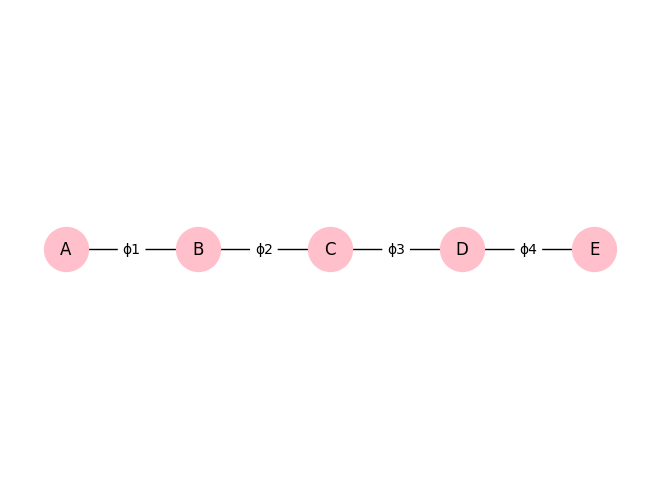

c = 0: coincide cu formula: True
c = 1: coincide cu formula: True


In [26]:
# Subiectul 2
# a)

pos = {v: (i, 0) for i, v in enumerate("ABCDE")}
G = nx.path_graph("ABCDE")
nx.draw(G, pos, with_labels=True, node_color="pink", node_size=1000)
nx.draw_networkx_edge_labels(G, pos, edge_labels={("A", "B"): "ϕ1", ("B", "C"): "ϕ2",
                                                  ("C", "D"): "ϕ3", ("D", "E"): "ϕ4"})
plt.show()
rng = np.random.default_rng(0)
phi1, phi2, phi3, phi4 = rng.uniform(0.1, 2, (4, 2, 2))

P = np.einsum("ab,bc,cd,de->abcde", phi1, phi2, phi3, phi4)
P /= P.sum()

# P(a | b, c) = P(a, b, c) / P(b, c)
P_abc = P.sum(axis=(3, 4))
P_a_dat_bc = P_abc / P_abc.sum(axis=0)

# formula simplificata: phi1(a, b) / suma dupa a' din phi1(a', b), fara c
formula = phi1 / phi1.sum(axis=0)

for c in range(2):
    print(f"c = {c}: coincide cu formula:", np.allclose(P_a_dat_bc[:, :, c], formula))

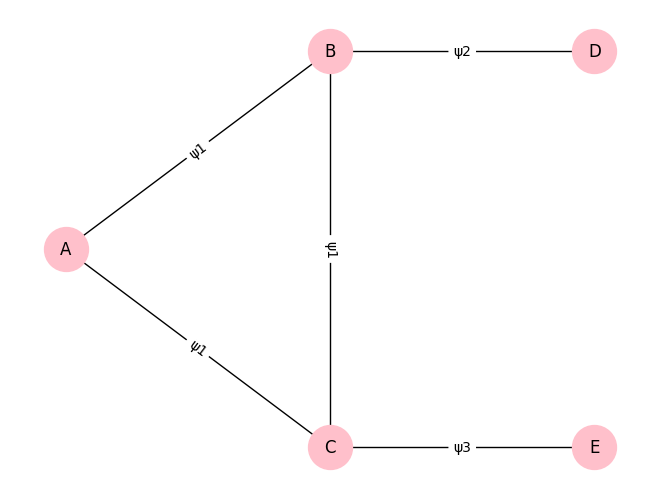

clici maximale: [['B', 'D'], ['A', 'B', 'C'], ['C', 'E']]
coincide cu formula: True


In [31]:
# b)
pos = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 1), "E": (2, -1)}
G = nx.Graph([("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("C", "E")])
nx.draw(G, pos, with_labels=True, node_color="pink", node_size=1000)
nx.draw_networkx_edge_labels(G, pos, edge_labels={("A", "B"): "ψ1", ("A", "C"): "ψ1", ("B", "C"): "ψ1",
                                                  ("B", "D"): "ψ2", ("C", "E"): "ψ3"})
plt.show()
print("clici maximale:", [sorted(c) for c in nx.find_cliques(G)])

rng = np.random.default_rng(0)
psi1 = rng.uniform(0.1, 2, (2, 2, 2))
psi2 = rng.uniform(0.1, 2, (2, 2))
psi3 = rng.uniform(0.1, 2, (2, 2))

P = np.einsum("abc,bd,ce->abcde", psi1, psi2, psi3)
P /= P.sum()

# P(d | a,b,c,e) = P(a,b,c,d,e) / suma dupa d din P(a,b,c,d,e)
P_d_dat_rest = P / P.sum(axis=3, keepdims=True)

# formula simplificata: psi2(b, d) / suma dupa d' din psi2(b, d')
formula = psi2 / psi2.sum(axis=1, keepdims=True)

print("coincide cu formula:", np.allclose(P_d_dat_rest, formula[None, :, None, :, None]))


posterior: Beta(7, 23)
media a posteriori: 0.23333333333333334


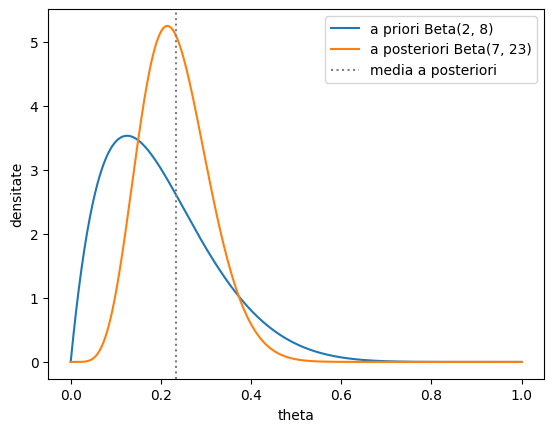

In [37]:
# Subiectul 3
# a)

a0, b0 = 2, 8
n, y = 20, 5

# posterior: beta(a0 + defecte, b0 + produse bune)
a1, b1 = a0 + y, b0 + n - y
print(f"posterior: Beta({a1}, {b1})")
print("media a posteriori:", a1 / (a1 + b1)) # 7/30 ~ 0.2333

theta = np.linspace(0, 1, 500)
plt.plot(theta, stats.beta.pdf(theta, a0, b0), label="a priori Beta(2, 8)")
plt.plot(theta, stats.beta.pdf(theta, a1, b1), label="a posteriori Beta(7, 23)")
plt.axvline(a1 / (a1 + b1), color="gray", linestyle=":", label="media a posteriori")
plt.xlabel("theta")
plt.ylabel("densitate")
plt.legend()
plt.show()

secvential: Beta(10, 35), deodata: Beta(10, 35)
media a posteriori: 0.2222222222222222


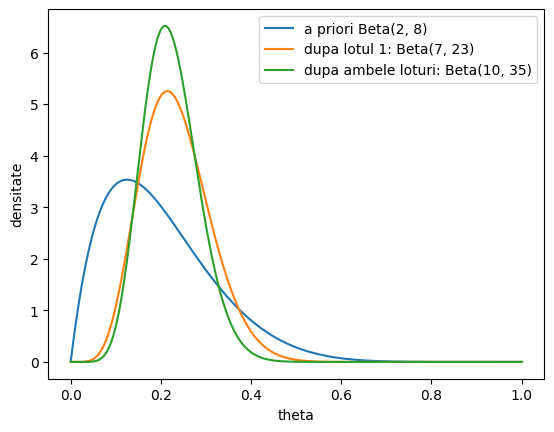

In [38]:
# b)

a0, b0 = 2, 8

a1, b1 = a0 + 5, b0 + (20 - 5) # beta(7, 23)

# lotul 2: 3 defecte din 15; posteriorul de la lotul 1 devine prior
a2, b2 = a1 + 3, b1 + (15 - 3) # beta(10, 35)

# verificare: ambele loturi deodata, 8 defecte din 35
a_total, b_total = a0 + 8, b0 + (35 - 8)
print(f"secvential: Beta({a2}, {b2}), deodata: Beta({a_total}, {b_total})")
print("media a posteriori:", a2 / (a2 + b2))

# densitatile pe acelasi grafic
theta = np.linspace(0, 1, 500)
plt.plot(theta, stats.beta.pdf(theta, a0, b0), label="a priori Beta(2, 8)")
plt.plot(theta, stats.beta.pdf(theta, a1, b1), label="dupa lotul 1: Beta(7, 23)")
plt.plot(theta, stats.beta.pdf(theta, a2, b2), label="dupa ambele loturi: Beta(10, 35)")
plt.xlabel("theta")
plt.ylabel("densitate")
plt.legend()
plt.show()

ambele loturi: Beta(10, 35), media = 0.222, std = 0.061, interval 95% = [0.115 0.353]
doar lotul 2: Beta(5, 20), media = 0.200, std = 0.078, interval 95% = [0.071 0.374]


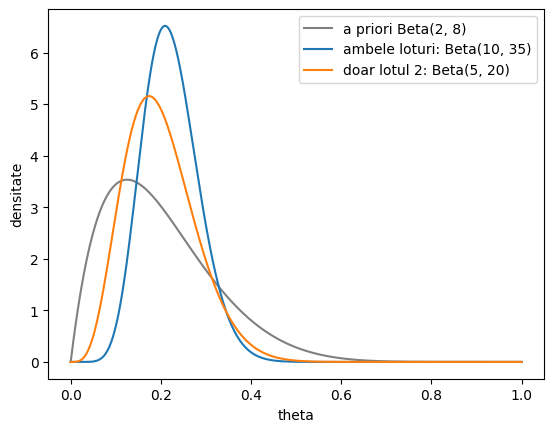

In [39]:
# c)

a0, b0 = 2, 8
a_ambele, b_ambele = a0 + 8, b0 + (35 - 8) # beta(10, 35)
a_lot2, b_lot2 = a0 + 3, b0 + (15 - 3) # beta(5, 20)

for nume, a, b in [("ambele loturi", a_ambele, b_ambele), ("doar lotul 2", a_lot2, b_lot2)]:
    d = stats.beta(a, b)
    print(f"{nume}: Beta({a}, {b}), media = {d.mean():.3f}, std = {d.std():.3f}, "
          f"interval 95% = {d.ppf([0.025, 0.975]).round(3)}")

theta = np.linspace(0, 1, 500)
plt.plot(theta, stats.beta.pdf(theta, a0, b0), "gray", label="a priori Beta(2, 8)")
plt.plot(theta, stats.beta.pdf(theta, a_ambele, b_ambele), label="ambele loturi: Beta(10, 35)")
plt.plot(theta, stats.beta.pdf(theta, a_lot2, b_lot2), label="doar lotul 2: Beta(5, 20)")
plt.xlabel("theta")
plt.ylabel("densitate")
plt.legend()
plt.show()